# DRM estimation with missing outcomes

Python translation of `algorithms.R`, the active `miss4` formulation in `eldrm(1).R`, and `nn_5_m.R`.

This notebook generates four populations, estimates response probabilities, imputes outcomes, estimates the DRM parameters, and examines **1,000 parallel Monte Carlo replications**. The included results use **1,000 observations per population**, 4,000 total, and one imputation draw per unit.

The accompanying README specifies the formulas, corrections to the R scripts, API mapping, failure policy, and validation. All Monte Carlo results below come from the Python simulation, rather than copied R results.

In [1]:
import os
# Set these before importing numerical libraries; process workers also limit threads.
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "eldrm.py").exists():
    ROOT = ROOT / "drm_python"
if not (ROOT / "eldrm.py").exists():
    raise RuntimeError("Open this notebook from the unzipped drm_python directory")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from data_generation import generate_missing_data
from algorithms import (
    kernel_propensity, score_propensity, random_kernel_imputation,
    deterministic_kernel_imputation, score_imputation,
    deterministic_linear_imputation, random_linear_imputation,
    cluster_imputation, random_kernel_odds_imputation, complete_data)
from eldrm import drmdel, eldrm_miss, negLDELfn, negLDELgr
from simulation import (
    SimulationConfig, METHODS, PARAMETERS, analyze_dataset,
    run_monte_carlo, load_monte_carlo, save_summary)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
RESULTS = ROOT / "results" / "n1000"
RESULTS.mkdir(parents=True, exist_ok=True)

## Generating model and missingness

For each population $r$, generate
\[
X_r\sim N(\mu_{Xr},\sigma_{Xr}^2),\qquad Y_r=a_r+b_rX_r+\varepsilon_r,
\quad\varepsilon_r\sim N(0,1.2^2).
\]
Then generate response indicators using
\[
P(\delta_r=1\mid X_r,Y_r)=0.1+0.9\operatorname{expit}(X_r-1).
\]
The missingness is MAR given the observed $X_r$. An independent false covariate $X_f\sim N(5,1.5^2)$ is retained for the misspecification comparisons. `y_full` is available only for the full-data oracle and evaluation; nuisance estimates use responding `y_obs` values.

In [2]:
N_PER_POPULATION = 1000
N_REPLICATIONS = 1000
SEED = 591
K = 1
config = SimulationConfig(n_samples=(N_PER_POPULATION,)*4,
                          n_replications=N_REPLICATIONS, seed=SEED, k=K)
data = generate_missing_data(config.n_samples, seed=SEED)
df = data.to_frame()
df.to_csv(RESULTS / "generated_dataset.csv", index=False)
display(df.groupby("population").agg(
    n=("delta", "size"), response_fraction=("delta", "mean"),
    full_mean=("y_full", "mean"), observed_mean=("y_obs", "mean")))
display(pd.DataFrame({"population": range(4),
    "marginal_mean": data.marginal_means,
    "marginal_variance": data.marginal_variances}))

,n,response_fraction,full_mean,observed_mean
population,,,,
0,1000,0.556,10.91526,11.24378
1,1000,0.541,10.53986,11.27467
2,1000,0.617,11.78043,12.42445
3,1000,0.560,12.24693,12.88517


,population,marginal_mean,marginal_variance
0,0,11.00,2.4400
1,1,10.50,4.6800
2,2,11.80,4.2624
3,3,12.21,4.1625


## Exact density-ratio parameters

The marginal outcome is normal with $\mu_r=a_r+b_r\mu_{Xr}$ and $v_r=b_r^2\sigma_{Xr}^2+1.2^2$. Therefore,
\[
\log(f_r/f_0)=\alpha_r+\beta_{r1}y+\beta_{r2}y^2,
\]
where
\[
\alpha_r=\frac12\log(v_0/v_r)+\frac{\mu_0^2}{2v_0}-\frac{\mu_r^2}{2v_r},\quad
\beta_{r1}=\mu_r/v_r-\mu_0/v_0,\quad
\beta_{r2}=\frac1{2v_0}-\frac1{2v_r}.
\]
The basis includes its intercept: $Q(y)=(1,y,y^2)^T$. Population 0 is the baseline and its parameter vector is fixed at zero.

In [3]:
truth = pd.Series(data.theta_true, index=PARAMETERS, name="truth")
display(pd.DataFrame(data.theta_true.reshape(3,3),
    index=["population 1", "population 2", "population 3"],
    columns=["alpha", "beta_y", "beta_y2"]))

,alpha,beta_y,beta_y2
population 1,12.69059,-2.26461,0.09808
population 2,8.18264,-1.73980,0.08761
population 3,6.62002,-1.57486,0.08480


## Demonstrate propensity estimation and all imputation methods

The R algorithms generate imputations for **all units**, including respondents. This is required by the augmented objective. `complete_data` fills only the missing outcomes when constructing a completed dataset.

Below, population 0 illustrates both propensity methods and all seven imputation methods. The subsequent 16-estimator analysis fits nuisance quantities separately in every population.

,true,kernel,score
count,1000.00000,1000.00000,1000.00000
mean,0.54548,0.55458,0.55600
std,0.18952,0.15937,0.18937
min,0.13510,0.15782,0.26000
25%,0.38641,0.45406,0.40000
50%,0.54905,0.49899,0.53000
75%,0.68741,0.70327,0.71000
max,0.95516,0.97574,0.88000


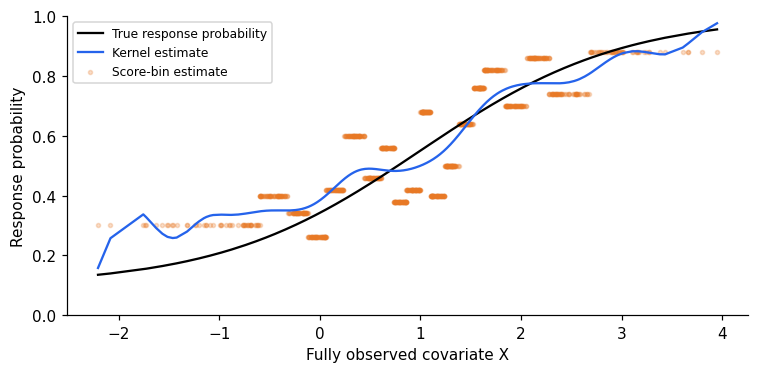

In [4]:
sl = data.slices[0]
x, y, delta = data.x_true[sl], data.y_obs[sl], data.delta[sl]
h_prop = len(x)**(-1/5) * x.std(ddof=1)
h_imp = len(x)**(-1/3) * x.std(ddof=1)
p_kernel = kernel_propensity(x, delta, h=h_prop)
p_score = score_propensity(x, delta, c=20)
display(pd.DataFrame({"true": data.propensity_true[sl],
                      "kernel": p_kernel, "score": p_score}).describe())
fig, ax = plt.subplots(figsize=(7,3.5))
order = np.argsort(x)
ax.plot(x[order], data.propensity_true[sl][order], color="black", label="True response probability")
ax.plot(x[order], p_kernel[order], color="#2563eb", label="Kernel estimate")
ax.scatter(x, p_score, s=7, alpha=.25, color="#e87925", label="Score-bin estimate")
ax.set(xlabel="Fully observed covariate X", ylabel="Response probability", ylim=(0,1))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [5]:
p_safe = np.clip(p_kernel, config.propensity_clip, 1-config.propensity_clip)
with threadpool_limits(limits=1):
    examples = {
        "random kernel": random_kernel_imputation(x,y,delta,h=h_imp,k=3,rng=101),
        "deterministic kernel": deterministic_kernel_imputation(x,y,delta,h=h_imp),
        "score hot deck": score_imputation(x,y,delta,c=20,k=3,rng=102),
        "deterministic linear": deterministic_linear_imputation(x,y,delta),
        "random residual linear": random_linear_imputation(x,y,delta,k=3,rng=103),
        "cluster hot deck": cluster_imputation(x,y,delta,c=10,k=3,rng=104),
        "odds-weighted kernel": random_kernel_odds_imputation(x,y,delta,p_safe,h=h_imp,k=3,rng=105),
    }
example_rows = []
for name, values in examples.items():
    completed = complete_data(y,delta,values)
    np.testing.assert_equal(completed[delta==1],
        np.repeat(y[delta==1,None],values.shape[1],axis=1))
    example_rows.append({"method":name,"shape":str(values.shape),
                         "mean_imputed_missing":values[delta==0].mean(),
                         "mean_completed":completed.mean()})
display(pd.DataFrame(example_rows).set_index("method"))

,shape,mean_imputed_missing,mean_completed
method,,,
random kernel,"(1000, 3)",10.61676,10.96538
deterministic kernel,"(1000, 1)",10.58661,10.95200
score hot deck,"(1000, 3)",10.58233,10.95010
deterministic linear,"(1000, 1)",10.58412,10.95089
random residual linear,"(1000, 3)",10.51003,10.91799
cluster hot deck,"(1000, 3)",10.63777,10.97471
odds-weighted kernel,"(1000, 3)",10.58121,10.94960


## Fit ordinary DEL and the missing-data augmented DEL

Let $g_i$ be a unit's population and $\rho_r=n_r/n$. The negative DEL contribution is
\[
\ell_i(\theta;y)=\log\left(\sum_r\rho_r e^{\theta_r^TQ(y)}\right)-\theta_{g_i}^TQ(y).
\]
`drmdel` minimizes $\sum_i\ell_i(\theta;y_i)$ using its analytic gradient.
The active R `miss4` objective is
\[
L_{aug}=\sum_i\left[\frac{\delta_i}{\hat p_i}\ell_i(\theta;y_i)+
\left(1-\frac{\delta_i}{\hat p_i}\right)\frac1k\sum_{\ell=1}^k
\ell_i(\theta;\tilde y_{i\ell})\right].
\]
With $\hat p_i=1$, this reduces to completed-data DEL. For larger $k$, average the nonlinear contributions, not imputed outcomes. Some augmented weights are negative: a fit passing score and positive-curvature checks is a **local candidate**, not a certified global optimum.

The `t/f` labels refer to the covariate used by each nuisance estimator. In `tf`, the first character selects imputation using the true covariate and the second selects propensity using the false covariate. Odds-weighted completion and augmented DEL are separate estimators.

In [6]:
with threadpool_limits(limits=1):
    fits, nuisance, errors = analyze_dataset(data, config, rng=np.random.default_rng(592))
if errors:
    print("Single-dataset fitting exceptions:", errors)
parameter_table = pd.DataFrame(
    {name: fits[name].mele if fits[name] is not None else np.full(9,np.nan)
     for name in METHODS}, index=PARAMETERS).T
parameter_table.loc["TRUTH"] = truth
parameter_table.to_csv(RESULTS / "single_dataset_parameters.csv")
display(parameter_table.round(5))
diagnostics = pd.DataFrame([
    {"method":name, "valid_candidate": fits[name].success if fits[name] else False,
     "scaled_score": fits[name].scaled_gradient_norm if fits[name] else np.nan,
     "min_scaled_curvature": fits[name].min_scaled_hessian_eigenvalue if fits[name] else np.nan,
     "BFGS_iterations": fits[name].nit if fits[name] else np.nan}
    for name in METHODS]).set_index("method")
display(diagnostics)
print("Propensity clipping counts:", nuisance["clip_counts"])

Propensity clipping counts: {'t': 2, 'f': 0}


,alpha_1,beta_y_1,beta_y2_1,alpha_2,beta_y_2,beta_y2_2,alpha_3,beta_y_3,beta_y2_3
cc_del,10.86486,-1.98333,0.08842,6.24768,-1.50817,0.08137,5.16367,-1.46099,0.08435
cc_custom,10.86486,-1.98333,0.08842,6.24768,-1.50817,0.08137,5.16367,-1.46099,0.08435
full_del,12.66392,-2.29354,0.10095,7.76171,-1.69236,0.08690,6.51188,-1.59548,0.08748
full_custom,12.66392,-2.29354,0.10095,7.76171,-1.69236,0.08690,6.51188,-1.59548,0.08748
kernel_t_del,12.44626,-2.22507,0.09673,7.62951,-1.65616,0.08478,5.21110,-1.36421,0.07744
kernel_t_aug,12.44626,-2.22507,0.09673,7.62951,-1.65616,0.08478,5.21110,-1.36421,0.07744
kernel_f_del,9.26209,-1.72648,0.07844,6.08902,-1.46016,0.07852,5.53177,-1.49789,0.08487
kernel_f_aug,9.26209,-1.72648,0.07844,6.08902,-1.46016,0.07852,5.53177,-1.49789,0.08487
odds_tt_del,14.39577,-2.58564,0.11289,8.28820,-1.78331,0.09078,4.79167,-1.31094,0.07607
augmented_tt,12.05646,-2.16368,0.09444,7.42580,-1.62508,0.08366,5.54313,-1.41376,0.07925


,valid_candidate,scaled_score,min_scaled_curvature,BFGS_iterations
method,,,,
cc_del,True,4.98892e-09,0.01224,38
cc_custom,True,4.98892e-09,0.01224,38
full_del,True,2.62209e-09,0.01453,38
full_custom,True,2.62209e-09,0.01453,38
kernel_t_del,True,2.57844e-09,0.01554,38
kernel_t_aug,True,2.57844e-09,0.01554,38
kernel_f_del,True,1.95158e-09,0.01354,38
kernel_f_aug,True,1.95158e-09,0.01354,38
odds_tt_del,True,3.61273e-09,0.01461,38


In [7]:
# Show exactly the estimated propensity and ordinary imputations used in the fits.
analysis_rows = df[["population","x_true","x_false","y_obs","delta"]].copy()
analysis_rows["p_hat_t"] = nuisance["p_t"]
analysis_rows["p_hat_f"] = nuisance["p_f"]
analysis_rows["y_tilde_t"] = nuisance["y_t"][:,0]
analysis_rows["y_tilde_f"] = nuisance["y_f"][:,0]
display(analysis_rows.head(12))

,population,x_true,x_false,y_obs,delta,p_hat_t,p_hat_f,y_tilde_t,y_tilde_f
0,0,1.48959,5.41091,NaN,0,0.64837,0.55191,12.54246,10.94169
1,0,0.08095,4.69845,NaN,0,0.40603,0.56619,9.34248,12.77975
2,0,0.17640,4.78856,11.60615,1,0.43569,0.57041,9.85819,7.44417
3,0,1.40234,3.00167,11.28019,1,0.61145,0.56327,10.72675,11.36401
4,0,0.51855,8.10337,11.79393,1,0.48948,0.61203,11.40390,12.02119
5,0,1.99618,5.66090,11.25507,1,0.77069,0.54937,10.99443,12.22827
6,0,-0.58286,4.32787,NaN,0,0.34768,0.54835,10.64976,9.32102
7,0,1.42662,4.92768,NaN,0,0.62166,0.57332,11.04346,8.73533
8,0,0.23379,4.73825,NaN,0,0.45286,0.56821,8.81182,10.42996
9,0,0.58393,6.47597,NaN,0,0.48725,0.58406,11.56494,11.01312


The package-versus-custom DEL rows share one Python fit because their formulas are identical. The kernel completion versus augmented `p=1` rows are also identical. These duplicate labels are retained to match the original R's 16 output rows; the remaining odds/augmented pairs are computed separately.

In [8]:
# An explicit wrapper call, with the estimated nuisance quantities just displayed.
fit_aug_tt = eldrm_miss(data.y_obs, nuisance["y_t"], data.delta,
                       nuisance["p_t"], data.n_samples,
                       compute_distribution=False)
np.testing.assert_allclose(fit_aug_tt.mele, fits["augmented_tt"].mele)
print("Augmented tt parameters:", fit_aug_tt.mele)
print("Passed local numerical checks:", fit_aug_tt.success)

Augmented tt parameters: [12.05645501 -2.16367589  0.09444102  7.42580416 -1.62507766  0.08366478
  5.54313454 -1.41375635  0.0792533 ]
Passed local numerical checks: True


## Parallel Monte Carlo: 1,000 replications

The simulation uses independent `SeedSequence` streams and standard process workers. Worker count does not change the draws. Importable workers support Jupyter and Windows. Checkpoints are written after each batch, and resuming requires an identical configuration.

The supplied run has already completed; the cell below loads it. Set `FORCE_RERUN=True` to reproduce it. Change the configuration and output directory together for another sample-size scenario.

Each fit records numerical validity, score, curvature and optimizer diagnostics. Failed candidates are retained in the raw output and excluded from the moment summaries with explicit counts. If failures occur, the resulting summaries are conditional on successful fits.

In [9]:
FORCE_RERUN = False
N_JOBS = 8  # reduce if memory is limited; -1 means all available CPUs
if (RESULTS / "monte_carlo.npz").exists() and not FORCE_RERUN:
    mc = load_monte_carlo(RESULTS)
    if mc["config"] != config:
        raise ValueError("Included result configuration differs; select a new output directory")
    print("Loaded", int(mc["completed"].sum()), "completed replications")
else:
    mc = run_monte_carlo(config, n_jobs=N_JOBS, output_dir=RESULTS,
                         resume=not FORCE_RERUN, batch_size=100)
summary = save_summary(mc, RESULTS)
assert int(mc["completed"].sum()) == N_REPLICATIONS
print("Sample sizes:", config.n_samples, "  k:", config.k, "  seed:", config.seed)
display(summary.groupby("method",sort=False)[["n_success","n_failed","failure_percent"]].first())

Loaded 1000 completed replications
Sample sizes: (1000, 1000, 1000, 1000)   k: 1   seed: 591


,n_success,n_failed,failure_percent
method,,,
cc_del,1000,0,0.0
cc_custom,1000,0,0.0
full_del,1000,0,0.0
full_custom,1000,0,0.0
kernel_t_del,1000,0,0.0
kernel_t_aug,1000,0,0.0
kernel_f_del,1000,0,0.0
kernel_f_aug,1000,0,0.0
odds_tt_del,1000,0,0.0


## RB and relative efficiency

For each parameter,
\[
RB(\%)=100\frac{\operatorname{mean}(\hat\theta)-\theta}{\theta},\qquad
MSE=\operatorname{mean}\{(\hat\theta-\theta)^2\}.
\]
The R script did not define RE. This implementation uses
\[
RE=\frac{MSE(\hat\theta_{full})}{MSE(\hat\theta_{method})},
\]
with both MSEs calculated on the same successful replications for the method and the reference. **RE is a ratio**: less than 1 means larger MSE than full data, and greater than 1 means smaller MSE in this experiment. RB is undefined for a true parameter of zero. The full-data benchmark has RE=1.

The R source incorrectly divides its 2,000-replication totals by 5,000. These summaries use actual successful replication counts.

In [10]:
rb = summary.pivot(index="method", columns="parameter", values="RB_percent").reindex(index=METHODS, columns=PARAMETERS)
re = summary.pivot(index="method", columns="parameter", values="RE").reindex(index=METHODS, columns=PARAMETERS)
print("Relative bias (%)")
display(rb.round(3))
print("Relative efficiency: full-data MSE / method MSE")
display(re.round(3))

Relative bias (%)
Relative efficiency: full-data MSE / method MSE


parameter,alpha_1,beta_y_1,beta_y2_1,alpha_2,beta_y_2,beta_y2_2,alpha_3,beta_y_3,beta_y2_3
method,,,,,,,,,
cc_del,-3.160,-3.509,-3.306,-15.937,-9.996,-6.878,-31.594,-15.421,-8.174
cc_custom,-3.160,-3.509,-3.306,-15.937,-9.996,-6.878,-31.594,-15.421,-8.174
full_del,0.389,0.332,0.273,0.179,0.139,0.115,0.287,0.281,0.277
full_custom,0.389,0.332,0.273,0.179,0.139,0.115,0.287,0.281,0.277
kernel_t_del,3.130,2.961,2.823,-0.331,-0.205,-0.099,-1.185,-0.538,-0.179
kernel_t_aug,3.130,2.961,2.823,-0.331,-0.205,-0.099,-1.185,-0.538,-0.179
kernel_f_del,-3.036,-3.370,-3.149,-15.813,-9.819,-6.665,-31.253,-15.090,-7.848
kernel_f_aug,-3.036,-3.370,-3.149,-15.813,-9.819,-6.665,-31.253,-15.090,-7.848
odds_tt_del,3.027,2.892,2.776,-0.622,-0.482,-0.361,-1.890,-1.144,-0.711


parameter,alpha_1,beta_y_1,beta_y2_1,alpha_2,beta_y_2,beta_y2_2,alpha_3,beta_y_3,beta_y2_3
method,,,,,,,,,
cc_del,0.418,0.443,0.476,0.321,0.389,0.445,0.204,0.293,0.377
cc_custom,0.418,0.443,0.476,0.321,0.389,0.445,0.204,0.293,0.377
full_del,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
full_custom,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
kernel_t_del,0.332,0.350,0.372,0.358,0.371,0.387,0.284,0.300,0.320
kernel_t_aug,0.332,0.350,0.372,0.358,0.371,0.387,0.284,0.300,0.320
kernel_f_del,0.328,0.349,0.375,0.274,0.327,0.369,0.181,0.250,0.312
kernel_f_aug,0.328,0.349,0.375,0.274,0.327,0.369,0.181,0.250,0.312
odds_tt_del,0.332,0.348,0.369,0.352,0.363,0.378,0.287,0.303,0.322


In [11]:
# Inspect detailed moments and Monte Carlo standard errors for a chosen method.
SELECTED_METHOD = "augmented_tt"
display(summary[summary.method == SELECTED_METHOD][[
    "parameter","truth","mean","bias","RB_percent","MSE","RE",
    "MCSE_mean","n_success","n_failed"]].set_index("parameter"))

,truth,mean,bias,RB_percent,MSE,RE,MCSE_mean,n_success,n_failed
parameter,,,,,,,,,
alpha_1,12.69059,13.11531,0.42472,3.34676,5.98564,0.27489,0.07623,1000,0
beta_y_1,-2.26461,-2.33694,-0.07233,3.19399,0.19079,0.29074,0.01363,1000,0
beta_y2_1,0.09808,0.10109,0.00300,3.06349,0.00037,0.31063,0.00060,1000,0
alpha_2,8.18264,8.14560,-0.03704,-0.45270,6.58024,0.29965,0.08115,1000,0
beta_y_2,-1.73980,-1.73418,0.00563,-0.32343,0.20448,0.31231,0.01431,1000,0
beta_y2_2,0.08761,0.08743,-0.00018,-0.21095,0.00039,0.32864,0.00062,1000,0
alpha_3,6.62002,6.56289,-0.05713,-0.86305,8.56339,0.23868,0.09257,1000,0
beta_y_3,-1.57486,-1.56845,0.00642,-0.40752,0.25496,0.25317,0.01597,1000,0
beta_y2_3,0.08480,0.08467,-0.00012,-0.14601,0.00046,0.27165,0.00068,1000,0


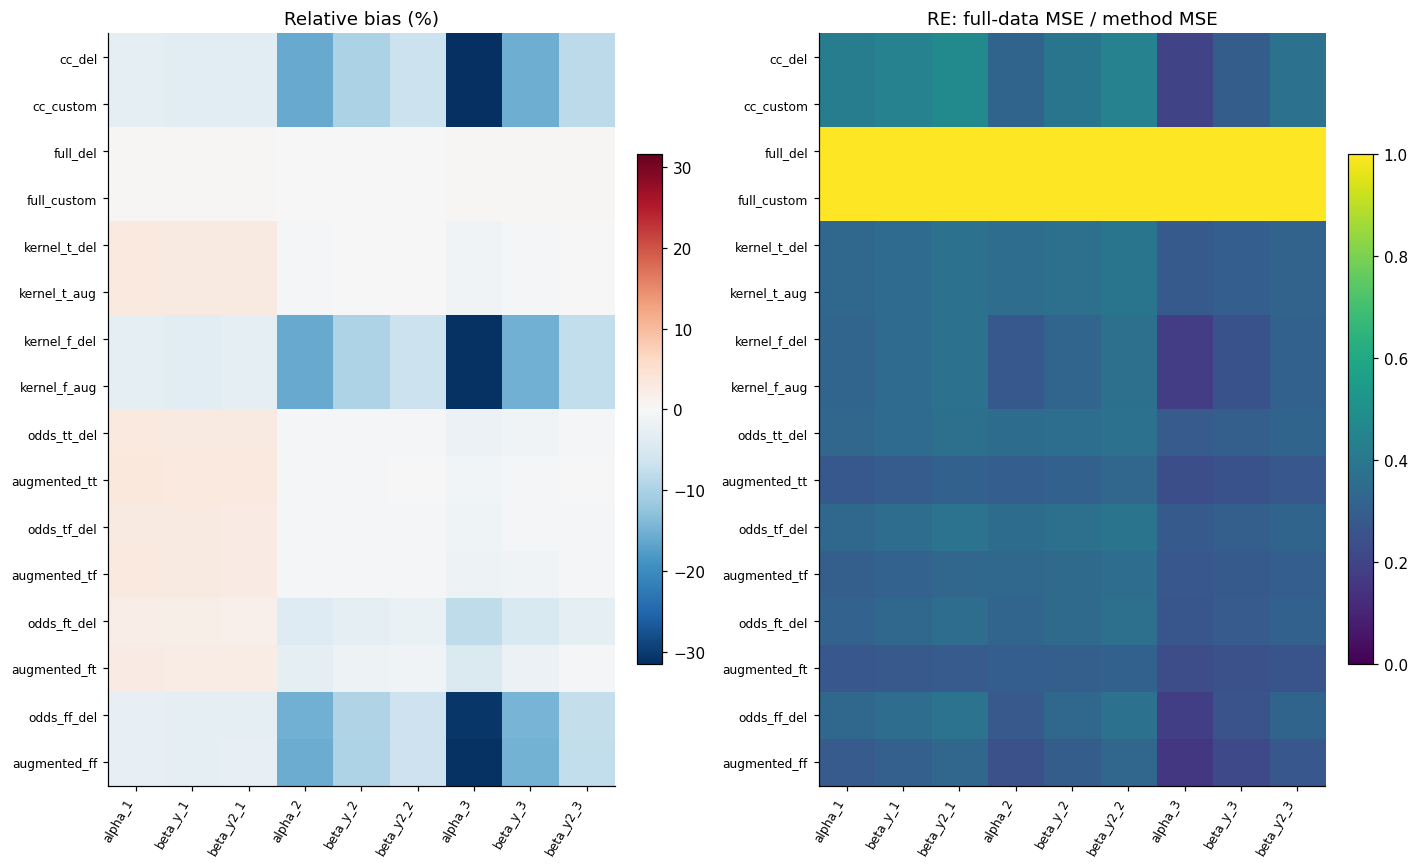

In [12]:
fig, axes = plt.subplots(1,2, figsize=(13,8))
rb_values = rb.to_numpy()
lim = max(1, float(np.nanmax(np.abs(rb_values))))
im0 = axes[0].imshow(rb_values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
im1 = axes[1].imshow(re.to_numpy(), aspect="auto", cmap="viridis", vmin=0)
for ax, table, title in zip(axes,[rb,re],["Relative bias (%)", "RE: full-data MSE / method MSE"]):
    ax.set_xticks(range(len(PARAMETERS)), PARAMETERS, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(METHODS)), METHODS, fontsize=8)
    ax.set_title(title)
fig.colorbar(im0, ax=axes[0], fraction=.046, pad=.04)
fig.colorbar(im1, ax=axes[1], fraction=.046, pad=.04)
fig.tight_layout()
fig.savefig(RESULTS / "RB_RE.png", dpi=180, bbox_inches="tight")
plt.show()

In [13]:
# Raw output dimensions are replication x method x parameter.
print("Raw estimate array:", mc["estimates"].shape)
print("Mean missing fraction by population:", mc["missing_fraction"].mean(axis=0))
print("Total clipped propensity values (true/false covariate):",
      mc["clipped_probabilities"].sum(axis=0))
print("Largest scaled score among accepted fits:",
      np.max(mc["scaled_gradient"][mc["success"]]))
print("Results written to:", RESULTS.relative_to(ROOT))
print("Files:", ", ".join(sorted(p.name for p in RESULTS.iterdir() if p.is_file())))

Raw estimate array: (1000, 16, 9)
Mean missing fraction by population: [0.450827 0.450275 0.36827  0.433859]
Total clipped propensity values (true/false covariate): [3294  158]
Largest scaled score among accepted fits: 9.999592770609693e-09
Results written to: results/n1000
Files: MSE.csv, RB.csv, RB_RE.png, RE.csv, failures.csv, generated_dataset.csv, metadata.json, monte_carlo.npz, single_dataset_parameters.csv, summary.csv


## Validation and interpretation

* All 17 numerical tests passed, including ordinary/augmented gradients and Hessians, exact Gaussian donor weights, empty-bin behavior, no missing-outcome leakage, exact normal density-ratio parameters, and serial/parallel reproducibility.
* The ordinary DEL objective and gradient were compared with the **actual compiled C core** from the supplied `drmdel` archive on identical inputs. Maximum absolute differences across 20 parameter vectors were about `5.7e-13` and `2.5e-11`. Fitted parameters differed by at most `7.4e-7`.
* An R runtime was unavailable; an end-to-end R `optim`/R RNG comparison was not run. The missing-data implementation was validated against independent scalar formulas and numerical derivatives.
* The augmented objective uses signed weights. Reported validity is a local numerical check, not a proof of a global MELE or theoretical double robustness. Assess any failures before interpreting moment comparisons.
* Estimated propensities and imputations are fitted within each population. The full-data benchmark is an oracle; it is unavailable in an actual missing-data analysis.
* Optional distribution outputs follow the R completed-support plug-in. The DEL Hessian is not a missing-data sampling covariance estimator.

For further experiments, adjust `SimulationConfig` or the generating-function arguments. Larger sample sizes, more imputation draws, additional seeds and uncertainty estimation are separate analyses; their results have not been substituted into this run.